<img src="https://www.udd.cl/dircom/web/udd/UDD.png" width="300">

---

# Taller de Obtención y Preparación de Datos
# Proyecto: *Del barril al bolsillo*
### Cómo la economía global (petróleo, cobre y dólar) llega al bolsillo de los chilenos · 2018–2026

**Ingeniería Civil en Informática · Semestre 2026-2**

---

| | |
|:---|:---|
| **Integrante 1** | *(completar)* |
| **Integrante 2** | *(completar)* |
| **Integrante 3** | *(completar)* |
| **Sección** | *(completar)* |
| **Docente** | *(completar)* |

---
## Contexto del proyecto

Chile es una economía pequeña y muy abierta al mundo. **Exporta cobre** (es el
principal productor mundial) e **importa casi todo el petróleo** que consume.
Por eso, lo que pasa en Londres, Nueva York o el Golfo Pérsico termina
apareciendo, semanas después, en la pizarra de la bencinera de la esquina,
en el precio del pan y en la cuenta del transporte.

2026 es un buen año para mirarlo con datos: las tensiones entre Estados Unidos
e Irán llevaron el barril de petróleo sobre los **US$100** en varios momentos
del año, el cobre marcó **máximos históricos** y el dólar en Chile cerró
septiembre en su **nivel más alto del año**. ¿Cómo se conectan estas tres
cosas? ¿Cuánto de lo que paga una familia chilena por la bencina depende
del mundo y cuánto de decisiones internas?

Este proyecto integra **fuentes de datos oficiales y reales**, de distinta
naturaleza y frecuencia:

| Archivo | Qué contiene | Fuente oficial | Frecuencia | Unidad |
|:---|:---|:---|:---|:---|
| `petroleo_brent_wti.csv` | Precio spot del petróleo Brent y WTI | EIA vía FRED (Fed de St. Louis) | Diaria (días hábiles EE.UU.) | US$ por barril |
| `dolar_observado.csv` | Dólar observado | Banco Central de Chile | Diaria (días hábiles Chile) | CLP por US$ |
| `cobre.csv` | Precio del cobre en la Bolsa de Metales de Londres | Cochilco / Banco Central de Chile | Diaria (días hábiles) | US$ por libra |
| `combustibles_chile.parquet` | Precios de combustibles en Chile, en un solo archivo que reúne **tres fuentes** de la CNE (columna `fuente`): encuesta mensual de precios en 16 ciudades, serie semanal de la Región Metropolitana (precio a público, precio de paridad y margen) y precios vigentes en cada estación de servicio (Bencina en Línea, 2-oct-2026) | Comisión Nacional de Energía (CNE) | Mensual, semanal y una fotografía por estación | CLP por litro (algunos gases en CLP por m³) |
| `ipc_chile.csv` | Variación mensual del Índice de Precios al Consumidor | INE / Banco Central de Chile | Mensual | % |

Período: **enero 2018 a septiembre/octubre 2026** (cada archivo tiene su propia
última fecha disponible: averígualo tú). Ese período incluye cuatro "shocks" que usaremos como
experimentos naturales: el **estallido social** (octubre 2019), la **pandemia**
(marzo 2020), la **invasión rusa a Ucrania** (febrero 2022) y el **conflicto
EE.UU.–Irán** (2026).

---
### **Objetivo del Análisis Exploratorio de Datos (EDA)**

El Análisis Exploratorio de Datos es una fase fundamental en cualquier proyecto
de análisis de datos que nos permite comprender la estructura, calidad y
características principales de nuestros datos antes de aplicar técnicas más
avanzadas. A través del EDA podremos identificar patrones, tendencias,
anomalías y relaciones entre variables que nos ayudarán a formular hipótesis
y guiar análisis posteriores.

En este proyecto aplicarán técnicas de EDA con NumPy, Pandas y visualizaciones
para analizar los datos descritos, siguiendo una metodología estructurada que
va desde la inspección inicial hasta el análisis de relaciones multivariadas.

---

### Reglas de oro del proyecto

> 1. **Todo análisis, conclusión o KPI debe estar basado en datos.**
>    Nunca afirmes algo que no puedas demostrar con una tabla o gráfico calculado
>    en este notebook.
>
> 2. **Los gráficos deben ser autoexplicativos:** título descriptivo, ejes
>    etiquetados con unidades (¡aquí las unidades importan mucho!), leyenda
>    cuando haya más de una serie, y fuente indicada.
>
> 3. **Elige el gráfico adecuado para cada análisis:** líneas para series de
>    tiempo, barras para comparar categorías, dispersión para relaciones entre
>    variables, mapas de calor para matrices de correlación, entre otros.
>
> 4. **Documenta tus decisiones:** cada vez que filtres, limpies, agregues
>    (por ejemplo, pasar de datos diarios a mensuales) o transformes datos,
>    explica brevemente el porqué en una celda Markdown.
>
> 5. **El notebook debe ser reproducible:** cualquier persona que lo ejecute
>    de principio a fin debe obtener los mismos resultados.
>
> 6. **Cuando uses información externa** (noticias, informes, metodologías),
>    indica la fuente con enlace.

---

### Sobre los archivos

- Los archivos `.csv` se leen con `pd.read_csv(...)`. Si ves caracteres raros en
  tildes o ñ, usa `encoding='utf-8-sig'`.
- `combustibles_chile.parquet` es un archivo Apache Parquet. Requiere `pyarrow` (`pip install pyarrow`).
- Ninguna columna de fecha viene convertida a `datetime`: esa es tu primera tarea.

> El archivo `Diccionario_TOPD2026-2_Proyecto.xlsx` describe cada columna de los
> cinco archivos, sus unidades, y el enlace a la fuente original.

---

---
---

# ENTREGA 1 — Exploración inicial y comprensión del problema
### Semana 11 · 18 de octubre 2026 hasta las 23:59 hrs a través de Canvas · **Ponderación: 20% de la nota del proyecto**

---

**Objetivo:** antes de analizar datos hay que *entender el problema*. Esta entrega
combina la exploración técnica de los datos con la construcción del marco
conceptual que guiará todo el trabajo posterior. Al terminarla deberás haber
respondido: *¿qué estoy mirando?, ¿en qué unidades y con qué calendario?,
¿qué me dicen estos datos a primera vista? y ¿qué quiero investigar en profundidad?*

---
## Sección 0 · Carga de datos

> Carga los cinco archivos. El único código que se entrega es la lectura;
> a partir de aquí todas las decisiones son tuyas.

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Carga — NO modificar estas líneas
df_pet  = pd.read_csv('petroleo_brent_wti.csv')          # Petróleo Brent y WTI
df_usd  = pd.read_csv('dolar_observado.csv')             # Dólar observado
df_cu   = pd.read_csv('cobre.csv')                       # Cobre
#df_comb = pd.read_parquet('combustibles_chile.parquet')  # Combustibles (3 fuentes CNE)
df_ipc  = pd.read_csv('ipc_chile.csv')                   # IPC (variación mensual)

---
## Sección 1.1 *(17 pts)* · Exploración técnica: mercados globales (petróleo y cobre)

Explora ambos datasets y responde las preguntas que siguen.
Apoya cada respuesta con el código y la salida que la justifica.

**1. *(3 pts)*** Obtén la información general de `df_pet` y `df_cu`: número de filas y
columnas, tipos de datos y uso de memoria. ¿Qué tipo de dato tiene la columna de
fecha? ¿Y las columnas de precio? Si alguna columna de precio no es numérica,
averigua por qué.

In [69]:
# Tu código aquí
### DF_PET ###
print('='*32 + ' DF_PET ' + '='*32)
print(f"Numero de filas y columnas: {df_pet.shape[0]} x {df_pet.shape[1]}")
print("Tipos de datos:")
print(df_pet.dtypes)
print('='*72)
print("Uso de memoria:")
print(df_pet.memory_usage())
print('='*72)

print(f"La columna de fecha es de tipo: {df_pet['fecha'].dtypes}")
print(f"Las columnas de precio son de tipo:\n{df_pet[['brent_usd_bbl', 'wti_usd_bbl']].dtypes}")

print("\n")

### DF_CU ###
print('='*32 + ' DF_CU ' + '='*32)
print(f"Numero de filas y columnas: {df_cu.shape[0]} x {df_cu.shape[1]}")
print("Tipos de datos:")
print(df_cu.dtypes)
print('='*72)
print("Uso de memoria:")
print(df_cu.memory_usage())
print('='*72)

print(f"La columna de fecha es de tipo: {df_cu['fecha'].dtypes}")
print(f"La columna de precio es de tipo: {df_cu['cobre_usd_lb'].dtypes}")

================================ DF_PET ================================
Numero de filas y columnas: 2282 x 3
Tipos de datos:
fecha                str
brent_usd_bbl    float64
wti_usd_bbl      float64
dtype: object
Uso de memoria:
Index              132
fecha            41076
brent_usd_bbl    18256
wti_usd_bbl      18256
dtype: int64
La columna de fecha es de tipo: str
Las columnas de precio son de tipo:
brent_usd_bbl    float64
wti_usd_bbl      float64
dtype: object


================================ DF_CU ================================
Numero de filas y columnas: 2178 x 2
Tipos de datos:
fecha               str
cobre_usd_lb    float64
dtype: object
Uso de memoria:
Index             132
fecha           69696
cobre_usd_lb    17424
dtype: int64
La columna de fecha es de tipo: str
La columna de precio es de tipo: float64


*Tu respuesta aquí*

**2. *(5 pts)*** ¿Qué período cubre cada serie? ¿Cuántas observaciones hay por año?
Si un año tiene 365 días, ¿por qué hay bastante menos registros?
¿Faltan exactamente los mismos días en el petróleo y en el cobre?

In [70]:
# Tu código aquí
#Primer se convierte las columnas de fecha a datetime
d_pet = pd.to_datetime(df_pet["fecha"]).dt.tz_localize(None).dt.normalize()
d_cu = pd.to_datetime(df_cu["fecha"]).dt.tz_localize(None).dt.normalize()

#Calcular periodo de cada serie
d_pet_min = d_pet.min()
d_cu_min = d_cu.min()
d_pet_max = d_pet.max()
d_cu_max = d_cu.max()

per_pet = d_pet_max - d_pet_min
per_cu = d_cu_max - d_cu_min

print("df_pet:", d_pet.min().date(), "a", d_pet.max().date())
print("df_cu:", d_cu.min().date(), "a", d_cu.max().date())
print("\n")

print("periodo de df_pet: ", per_pet)
print("periodo de df_cu: ", per_cu)
print("o en años")
años_pet = per_pet / pd.Timedelta(days=365.25)
años_cu = per_cu / pd.Timedelta(days=365.25)
print("periodo de df_pet: ", años_pet)
print("periodo de df_cu: ", años_cu)

conteo_pet = d_pet.dt.year.value_counts().sort_index()
conteo_cu = d_cu.dt.year.value_counts().sort_index()

print("Observaciones por año calendario (petróleo):")
print(conteo_pet)
print("\nObservaciones por año calendario (cobre):")
print(conteo_cu)


#Imprimir cantidad de datos
print(f"Numero de filas por año: {df_pet.shape[0]/años_pet}")
print(f"Numero de filas por año: {df_cu.shape[0]/años_cu}")
print("Aqui se puede ver claramente que se tienen menos que 365 dias, quizas son la cantidad de dias habiles.")
print(d_pet.dt.dayofweek.value_counts().sort_index())
print(d_cu.dt.dayofweek.value_counts().sort_index())
print("Como se puede ver solo hay dias habiles. Y la diferencia entre dias son dias feriados.")

#Exactamente los mismos dias?
inicio = max(d_pet_min, d_cu_min)
fin = min(d_pet_max, d_cu_max)
#dias hábiles
todos_habiles = pd.bdate_range(inicio, fin)
fechas_pet = d_pet[(d_pet >= inicio) & (d_pet <= fin)]
fechas_cu = d_cu[(d_cu >= inicio) & (d_cu <= fin)]

f1 = todos_habiles.difference(fechas_pet.to_list())
f2 = todos_habiles.difference(fechas_cu.to_list())


solo_pet = f1.difference(f2)
solo_cu = f2.difference(f1)
ambos = f1.intersection(f2)

print(f"Faltan solo en petroleo: {len(solo_pet)}")
print(f"Faltan solo en cobre: {len(solo_cu)}")
print(f"Faltan en ambos: {len(ambos)}")

print("se puede ver que no faltan los mismos dias.")

df_pet: 2018-01-01 a 2026-09-29
df_cu: 2018-01-02 a 2026-10-02


periodo de df_pet:  3193 days 00:00:00
periodo de df_cu:  3195 days 00:00:00
o en años
periodo de df_pet:  8.7419575633128
periodo de df_cu:  8.747433264887064
Observaciones por año calendario (petróleo):
fecha
2018    261
2019    261
2020    262
2021    261
2022    260
2023    260
2024    262
2025    261
2026    194
Name: count, dtype: int64

Observaciones por año calendario (cobre):
fecha
2018    246
2019    248
2020    251
2021    250
2022    250
2023    247
2024    248
2025    248
2026    190
Name: count, dtype: int64
Numero de filas por año: 261.03993109927967
Numero de filas por año: 248.98732394366195
Aqui se puede ver claramente que se tienen menos que 365 dias, quizas son la cantidad de dias habiles.
fecha
0    457
1    457
2    456
3    456
4    456
Name: count, dtype: int64
fecha
0    430
1    442
2    441
3    439
4    426
Name: count, dtype: int64
Como se puede ver solo hay dias habiles. Y la diferencia entre

*Tu respuesta aquí*

**3. *(5 pts)*** Encuentra el valor mínimo del WTI en todo el período, con su fecha.
¿Es un error de los datos o ocurrió de verdad? Investiga qué pasó ese día
(incluye la fuente) y explica con tus palabras cómo un precio puede llegar a
ese valor. ¿Le pasó lo mismo al Brent ese día?

In [71]:
# Tu código aquí
min_wti = df_pet["wti_usd_bbl"].min()
print("El valor minimo de WTI es:", min_wti)
idx_min_wti = df_pet['wti_usd_bbl'].idxmin()
print("en el indice:", idx_min_wti)

fecha = df_pet.iloc[idx_min_wti]["fecha"]
print("la fecha del dia con menor valor es:",fecha)

#brent en el mismo dia
print("brent en el mismo dia:\n", df_pet[df_pet["fecha"] == fecha])

#https://www.infobae.com/america/mundo/2020/04/20/el-precio-del-crudo-de-eeuu-cayo-casi-20-por-debajo-de-los-15-dolares-el-barril/

El valor minimo de WTI es: -36.98
en el indice: 600
la fecha del dia con menor valor es: 2020-04-20
brent en el mismo dia:
           fecha  brent_usd_bbl  wti_usd_bbl
600  2020-04-20          17.36       -36.98


*Tu respuesta aquí*

**4. *(4 pts)*** El petróleo se mide en US$ por barril, el cobre en US$ por libra y
la bencina en pesos por litro. ¿Cuántos litros tiene un barril de petróleo?
¿Por qué es indispensable resolver las unidades *antes* de comparar el precio
del petróleo con el de la bencina? Escribe la fórmula que usarías para expresar
el precio del barril en pesos chilenos por litro.

*Tu respuesta aquí*

---
## Sección 1.2 *(23 pts)* · Exploración técnica: Chile (dólar, combustibles e IPC)

**5. *(5 pts)*** Explora `df_usd`. ¿Qué período cubre? ¿La columna de fecha trae solo la
fecha o también una hora o zona horaria? Si trae hora, ¿qué problema podría
aparecer al cruzarla con el petróleo por fecha? Investiga en la metodología del
Banco Central: el dólar observado publicado un día, ¿a las transacciones de qué
día corresponde? (incluye la fuente)

In [72]:
# Tu código aquí

*Tu respuesta aquí*

**6. *(6 pts)*** Explora `df_comb`. El archivo reúne tres fuentes distintas (columna
`fuente`): ¿qué representa exactamente una fila en cada una? Para cada fuente
describe su cobertura: período, territorio (regiones, ciudades o comunas),
cantidad de estaciones, combustibles y variables (`variable`). ¿Qué tipo de dato
tiene la columna `valor` y por qué? ¿Todas las estaciones venden todos los
combustibles? ¿Qué significan los códigos de combustible que empiezan con "A"?

In [73]:
# Tu código aquí

*Tu respuesta aquí*

**7. *(6 pts)*** Calcula, para cada año, el precio promedio nacional de la bencina de
93 octanos y del diésel. ¿Cuánto subió cada uno (en %) entre 2018 y el último
año completo disponible? ¿Es razonable promediar todas las filas de `df_comb`
directamente, o hay algo en la estructura de los datos que podría sesgar ese
promedio? (piensa en las tres fuentes, en la variable y en el peso de cada
ciudad). Justifica qué filas usaste.

In [74]:
# Tu código aquí

*Tu respuesta aquí*

**8. *(6 pts)*** Para cruzar las fuentes necesitarás una clave temporal común.
Construye una tabla que resuma, para cada uno de los datasets con fecha: frecuencia,
primera fecha, última fecha y cantidad de fechas distintas. Revisa con atención
las fechas de la encuesta mensual: ¿se hace siempre el mismo día del mes?
¿Las fechas coinciden entre combustibles? ¿Qué pasaría si cruzas por fecha
exacta? ¿Qué granularidad común (día, semana, mes) usarías para cruzar las fuentes? ¿Qué ganas y
qué pierdes con esa decisión? Revisa además `df_ipc`: ¿contiene el *nivel* del
índice o su *variación*? ¿Qué implica eso para compararlo con los demás?

In [75]:
# Tu código aquí

*Tu respuesta aquí*

---
## Sección 2 *(30 pts)* · Comprensión del problema e hipótesis iniciales

> Esta sección es conceptual. No hay código, solo análisis y razonamiento.
> Es la parte más importante de la Entrega 1 porque define la dirección
> de todo el trabajo posterior.
>
> Formula tus **hipótesis iniciales**, lo que *crees* que encontrarás,
> *antes* de hacer el análisis en profundidad. No hay respuestas
> correctas o incorrectas en esta etapa.

---

### Las grandes preguntas del proyecto

A lo largo del proyecto deberás responder estas cinco preguntas centrales.

---
#### **Pregunta 1 *(3 pts)*** — ¿El cobre sostiene al peso?
> Se dice que "cuando sube el cobre, baja el dólar en Chile". ¿Los datos lo
> confirman? ¿La relación es igual de fuerte todos los años, o hay períodos
> en que se rompe? ¿Qué pasó en 2026, con cobre en máximos y dólar alto a la vez?
 
**Hipótesis inicial** *(¿qué esperas encontrar y por qué?)*:
 
Creo que sí es el caso. Cuando el cobre sube, el país tiene mayor ingreso y por lo tanto el dólar en Chile baja. No creo que la relación siempre sea igual de fuerte: en 2026 ocurrió el conflicto de EE.UU. con Irán, lo cual desestabilizó el mercado, y el dólar y el cobre subieron. Creo que el dólar y el cobre pudieron subir juntos en 2026 porque el conflicto afecta a las monedas de países emergentes.
 
**¿Qué datos y variables necesitas para responderla?**
 
Los datos necesarios son el valor del cobre, el valor del dólar en Chile, y calcular cómo se relacionan a través de los años.
 
---
 
#### **Pregunta 2 *(3 pts)*** — Del barril al surtidor
> ¿Cuánto y con cuánto retraso se traspasa un alza del petróleo (medido en
> pesos) al precio de la bencina en Chile? ¿Las bencinas suben tan rápido
> como bajan?
 
**Hipótesis inicial:**
 
Yo creo que el alza de la bencina se demorará una semana, ya que las bencineras deben tener un stock. El alza no debería ser proporcional, porque parte del precio son impuestos fijos. Las bencinas no creo que bajen tan rápido como suben.
 
**¿Qué datos y variables necesitas?**
 
Se necesitan datos del precio del petróleo (en pesos), la fecha del petróleo y la bencina, y el precio de la bencina en Chile. Hay que estudiar cómo se relacionan los precios con el retraso.
 
---
 
#### **Pregunta 3 *(3 pts)*** — Las crisis como experimentos naturales
> Estallido social (oct 2019), pandemia (mar 2020), invasión a Ucrania
> (feb 2022) y conflicto EE.UU.–Irán (2026). ¿Qué variable reaccionó más
> en cada crisis? ¿Todas las crisis afectaron igual al petróleo, al cobre,
> al dólar y a la bencina? ¿Cuál se recuperó más rápido?
 
**Hipótesis inicial:**
 
Yo creo que la variable más afectada depende de cada crisis, entonces no las afectaron de la misma manera. Espero que el estallido social afecte el dólar, la invasión a Ucrania el dólar, el petróleo y la bencina, y el conflicto EE.UU.–Irán el dólar, la bencina y el petróleo. La pandemia debería haber bajado el petróleo y el cobre. Creo que el dólar se recuperó más lento que ellos.
 
**¿Qué datos y variables necesitas?**
 
Se necesitan datos de la fecha, precios de petróleo, cobre, bencina y dólar en Chile. Hay que ver cómo cambian los precios a través de las fechas cercanas a estos eventos importantes.
 
---
 
#### **Pregunta 4 *(3 pts)*** — La geografía del precio
> ¿Un litro de bencina cuesta lo mismo en Arica, Santiago y Punta Arenas?
> ¿Qué regiones pagan más y cuáles menos? ¿Esa diferencia es estable en el
> tiempo o cambia cuando el petróleo se dispara?
 
**Hipótesis inicial:**
 
No cuestan lo mismo. Espero que las regiones donde sea más difícil el acceso sean más caras, y las que no estén cerca de petroleras también. Esa diferencia se mantiene estable en relación a las regiones, pero la diferencia en pesos debería ser parecida aunque suba el petróleo, porque el transporte y los impuestos son costos fijos.
 
**¿Qué datos y variables necesitas?**
 
Se necesitan datos de regiones y sus precios de bencina. También hay que agregar la fecha para ver cómo cambia con el tiempo.
 
---
 
#### **Pregunta 5 *(3 pts)*** — Escenarios para fin de 2026
> Si el Brent se mantiene alto, ¿cuánto debería costar la bencina de 93 en
> diciembre de 2026? ¿Es posible construir una estimación simple, sin modelos
> de IA, a partir de la relación histórica entre petróleo, dólar y bencina?
> ¿Qué supuestos implica y cuáles son sus limitaciones?
 
**Hipótesis inicial:**
 
Si el Brent se mantiene alto, la bencina también va a estar alta. Sí es posible realizar una estimación simple.
 
**¿Cómo diseñarías esa estimación? Describe el método antes de implementarlo.**
 
Primero hay que ver cómo se relaciona el precio del Brent con la bencina históricamente, incorporando también el retraso del petróleo. Asumiendo que el Brent mantiene un precio similar, podríamos ver a cuánto va a estar la bencina. Para estimarlo usaría una regresión simple entre el cambio de la bencina y el cambio del Brent en pesos, con rezago. Asumo que el dólar y el MEPCO se mantienen.
 
---
 
### Reflexión crítica sobre las fuentes
 
**9. *(4 pts)*** Investiga qué es el MEPCO (Mecanismo de Estabilización de Precios de
los Combustibles). ¿Cómo funciona, en simple? ¿Cómo debería afectar la relación
entre el precio del petróleo y el precio de la bencina que observarás en los
datos? *(incluye la fuente consultada)*
 
El MEPCO es un mecanismo creado por la ley N°20.765 para estabilizar los precios de venta interna de combustibles. Este mecanismo incrementa y rebaja los impuestos a los combustibles, evitando cambios demasiado bruscos. Funciona de manera que cada semana se compara el precio de importación con unos precios de referencia y se verifica que no sean demasiado diferentes.
 
El MEPCO debería hacer que los precios de la bencina se muevan más suavemente y que se demore un poco más en verse el efecto. Por eso la bencina debería moverse más lento que el petróleo y con rezago.
 
Fuente:
https://www.cne.cl/en/tarificacion/hidrocarburos/mecanismo-de-estabilizacion-de-precios-de-los-combustibles-mepco/
 
---
 
**10. *(4 pts)*** Entre 2018 y 2026 el dólar y el IPC acumulado subieron. Si calculas la
correlación entre ambos *niveles* obtendrás un número alto. ¿Eso demuestra que
uno causa al otro? ¿Qué otra explicación puede tener que dos series que
crecen en el tiempo aparezcan muy correlacionadas? ¿Cómo podrías
comparar las series para evitar esa trampa?
 
No necesariamente, correlación no demuestra causalidad. Puede que ambas cambien de manera similar por otra razón, la cual podría ser que las dos series tienen tendencia al alza.
Para evitar esta trampa se podría estudiar cómo cambió cada una por separado con respecto al tiempo en vez de comparar los niveles.
 
---
 
**11. *(4 pts)*** El dataset trae dos petróleos: Brent y WTI. ¿En qué se diferencian?
Investiga qué referencia internacional usa Chile para fijar el precio de
paridad de importación de los combustibles. Según eso, ¿cuál de las dos
series usarás como principal y por qué? *(incluye la fuente)*
 
Brent y WTI son dos tipos de petróleo diferentes, con diferente composición y precio. El Brent viene del Mar del Norte y el WTI de Texas, y el WTI es de mejor calidad.
Según la CNE, Chile usa Brent, por eso usaré Brent como principal.
 
Fuente:
(https://www.cne.cl/en/tarificacion/hidrocarburos/mecanismo-de-estabilizacion-de-precios-de-los-combustibles-mepco/53815-2/)
 
---
 
**12. *(3 pts)*** Un compañero afirma: "la bencina en 2026 cuesta mucho más que en 2018,
así que hoy es mucho más cara para las familias". ¿Qué le falta a ese
razonamiento? ¿Qué dataset del proyecto te permite corregirlo y cómo?
 
A ese razonamiento le falta tomar en cuenta la inflación y los ingresos de las familias. El dataset que nos permite corregirlo es el IPC con esto podemos "anular" el efecto de la inflación. Con el IPC acumulo la variación mensual en un índice y con eso expreso la bencina en pesos reales.


---
## Sección 3 *(30 pts)*· Primer vistazo a los datos

> Construye los gráficos y tablas que consideres necesarios para familiarizarte
> con los datos. Los requisitos son:
> - Al menos **3 visualizaciones** (mercados globales, Chile y una comparativa)
> - Cada gráfico debe ser autoexplicativo (ver reglas de oro)
> - Cada gráfico debe ir acompañado de una interpretación escrita

---

**13. *(8 pts)*** Grafica la evolución del Brent, el WTI y el cobre entre 2018 y la fecha de
corte. Marca en el gráfico las cuatro crisis del proyecto.
¿Cuál de las crisis se ve más claramente en cada serie?
*(Pista: el petróleo y el cobre están en unidades distintas; piensa cómo
mostrarlos sin que uno aplaste al otro.)*

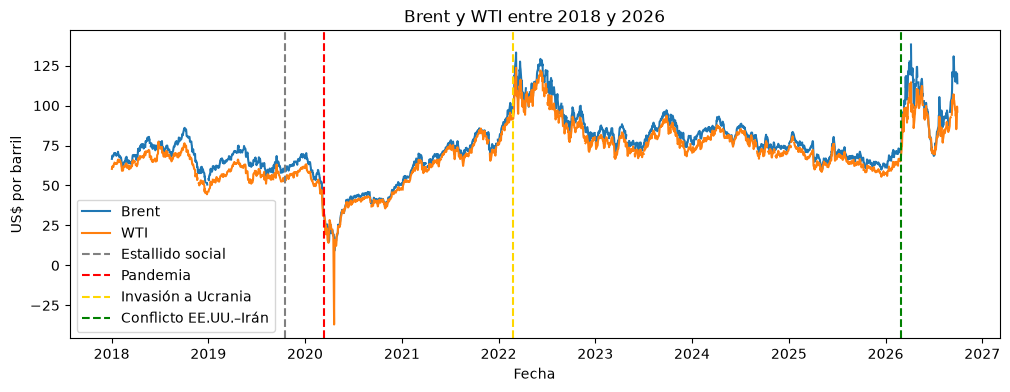

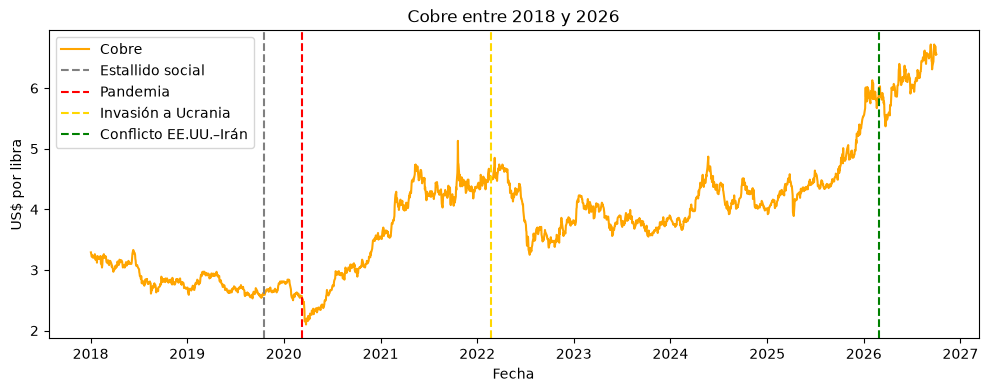

In [ ]:
Estallido = pd.Timestamp('2019-10-18')
Pandemia = pd.Timestamp('2020-03-11')
Invasion = pd.Timestamp('2022-02-24')
Conflicto = pd.Timestamp('2026-03-01')

# Fechas a datetime
x_pet = pd.to_datetime(df_pet['fecha']).dt.tz_localize(None)
x_cu = pd.to_datetime(df_cu['fecha']).dt.tz_localize(None)

# Gráfico 1: petróleo (US$ por barril)
plt.figure(figsize=(12, 4))
plt.plot(x_pet, df_pet['brent_usd_bbl'], label='Brent')
plt.plot(x_pet, df_pet['wti_usd_bbl'], label='WTI')
plt.axvline(Estallido, color='gray', linestyle='--', label='Estallido social')
plt.axvline(Pandemia, color='red', linestyle='--', label='Pandemia')
plt.axvline(Invasion, color='gold', linestyle='--', label='Invasión a Ucrania')
plt.axvline(Conflicto, color='green', linestyle='--', label='Conflicto EE.UU.-Irán')
plt.title("Brent y WTI entre 2018 y 2026")
plt.xlabel("Fecha")
plt.ylabel("US$ por barril")
plt.legend()
plt.show()

# Gráfico 2: cobre (US$ por libra), aparte porque tiene otra unidad
plt.figure(figsize=(12, 4))
plt.plot(x_cu, df_cu['cobre_usd_lb'], color='orange', label='Cobre')
plt.axvline(Estallido, color='gray', linestyle='--', label='Estallido social')
plt.axvline(Pandemia, color='red', linestyle='--', label='Pandemia')
plt.axvline(Invasion, color='gold', linestyle='--', label='Invasión a Ucrania')
plt.axvline(Conflicto, color='green', linestyle='--', label='Conflicto EE.UU.-Irán')
plt.title("Cobre entre 2018 y 2026")
plt.xlabel("Fecha")
plt.ylabel("US$ por libra")
plt.legend()
plt.show()

*Tu interpretación aquí*

**14. *(8 pts)*** Grafica la evolución del dólar observado y del precio promedio nacional de
la bencina 93 y el diésel. ¿Se mueven juntos? ¿En qué períodos se separan?

In [77]:
# Tu código aquí

*Tu interpretación aquí*

**15. *(10 pts)*** Construye un índice base 100 (por ejemplo, promedio de enero 2018 = 100)
para Brent, cobre, dólar y bencina 93, con frecuencia mensual, y grafícalos
juntos. ¿Cuál creció más en el período? ¿Cuál es el más volátil a simple vista?
¿Por qué un índice base 100 permite comparar series que están en unidades
distintas?

In [78]:
# Tu código aquí

*Tu interpretación aquí*

**16. *(4 pts)*** En base a todo lo explorado en esta Entrega 1, ¿cuáles son los
3 análisis que priorizarás en la Entrega 2? Justifica brevemente por qué.

*Tu respuesta aquí*

---
## Checklist Entrega 1

Antes de enviar, verifica:

- [ ] Todas las celdas de código ejecutan sin errores de principio a fin
- [ ] Las preguntas 1 a 8 están respondidas con código y salida que las justifica
- [ ] Las hipótesis iniciales de las 5 grandes preguntas están redactadas (Sección 2)
- [ ] Las preguntas de reflexión crítica 9 a 12 están respondidas, con fuentes
- [ ] Los 3 gráficos tienen título, ejes con unidades, leyenda y fuente
- [ ] Los nombres de los integrantes están en la portada

---
---

# ENTREGA 2 — Análisis en profundidad y construcción de KPIs
### Semana 15 · 15 de noviembre de 2026 hasta las 23:59 hrs a través de Canvas · **Ponderación: 40% de la nota del proyecto**

---

**Objetivo:** responder las grandes preguntas del proyecto con análisis
rigurosos. Esta entrega comienza con la limpieza de los datos, sigue con la
construcción de una **tabla mensual integrada** que une las fuentes, y
termina con conclusiones fundamentadas y KPIs propios.

> **Recuerda:** a partir de la Parte II trabajas con los datasets limpios
> que construirás en la Parte I (`df_mercado_clean`, `df_comb_clean` y
> `df_mes`). Nunca con los originales.

---
## Parte I · Evaluación de calidad, limpieza y dataset final *(20 pts)*

> Los datos reales no llegan perfectos, y en este proyecto **nadie
> "ensució" los datos a propósito**: todo lo que encuentres es cómo vienen
> de la fuente. Esta sección tiene tres etapas: **detectar** los problemas,
> **decidir** cómo tratarlos con criterio analítico, y **construir los
> datasets limpios**.
>
> Cada decisión debe documentarse: explica el **qué**, el **por qué**
> y el **impacto esperado** sobre el análisis.
>
> Trabaja siempre sobre copias, nunca sobreescribas el dataframe original.

---

### I.1 Diagnóstico *(6 pts)* — Series de mercado (petróleo, cobre, dólar)

**17. *(2 pts)*** Cuantifica los valores faltantes en las tres series de mercado.
¿Corresponden a errores o a días sin cotización (fines de semana, feriados)?
Verifica con ejemplos concretos: toma 3 fechas faltantes y averigua qué día era.
¿Los días sin dato del petróleo (calendario de EE.UU.) coinciden con los del
dólar observado (calendario de Chile)?

In [79]:
# Tu código aquí

*Tu análisis aquí*

**18. *(3 pts)*** Detecta valores atípicos. En series de precios, un valor "alto" no es
necesariamente un error (el petróleo puede estar caro durante meses). Por eso,
en vez de buscar outliers en el nivel del precio, búscalos en la
variación diaria (`pct_change`). Usa el método que consideres adecuado,
justifícalo y muestra los 5 días con mayor variación (positiva o negativa) de
cada serie. ¿Son errores o eventos reales? Verifica al menos dos con noticias.

In [80]:
# Tu código aquí

*Tu análisis aquí*

**19. *(1 pts)*** Verifica que cada serie tenga una sola observación por fecha y que
las unidades sean consistentes en todo el período (por ejemplo, que el cobre
no cambie de US$/lb a centavos de dólar en algún tramo). Documenta lo que
encuentres.

In [81]:
# Tu código aquí

*Tu análisis aquí*

---
### I.2 Diagnóstico *(12 pts)* — Combustibles

**20. *(3 pts)*** En `df_comb`, cuantifica por fuente los valores faltantes y los
valores de `valor` que no son números (busca textos que se hayan colado en la columna de
precio: ¿de dónde crees que viene cada uno? Pista: el archivo original de la
CNE es una planilla Excel). ¿En qué ciudades, combustibles y fechas se
concentran? ¿Un faltante significa que el combustible no se vende ahí, o que no
se midió? ¿Deben tratarse igual?

In [82]:
# Tu código aquí

*Tu análisis aquí*

**21. *(2 pts)*** Busca duplicados usando la clave lógica correcta para cada fuente
(piensa qué combinación de columnas debería identificar un registro único).
Si los encuentras, muestra ejemplos y describe qué los diferencia entre sí.
En las estaciones, la columna `fecha` es la última actualización del precio:
¿todas las estaciones actualizaron su precio recientemente? ¿Qué harías con un precio que no se actualiza hace meses?

In [83]:
# Tu código aquí

*Tu análisis aquí*

**22. *(4 pts)*** En las estaciones de `df_comb`, detecta precios imposibles o sospechosos (precios en
cero, negativos, o fuera de todo rango razonable para ese combustible; ojo:
no todos los combustibles se cobran por litro). Luego detecta outliers con IQR
de dos formas: global (todo el país junto) y local (por combustible y
región). ¿Cuántos registros marca cada método? ¿Cuál es más adecuado y por qué?
Para los casos más extremos, compara con las estaciones de la misma comuna y
con la encuesta mensual de esa región: ¿es un error de digitación o un precio real?

In [84]:
# Tu código aquí

*Tu análisis aquí*

**23. *(3 pts)*** Revisa la consistencia de las columnas geográficas y de tipo de
combustible entre las tres fuentes: ¿una misma región se escribe de más de
una forma (números romanos, nombres, mayúsculas, tildes, espacios)? ¿Los nombres
de combustible son uniformes? Muestra los casos que encuentres y construye una
tabla de equivalencias que permita comparar la encuesta mensual con las estaciones.

In [85]:
# Tu código aquí

*Tu análisis aquí*

---
### I.3 Limpieza y datasets finales *(12 pts)*

**24. *(4 pts)*** Construye **`df_mercado_clean`**: una sola tabla diaria que una
petróleo, cobre y dólar por fecha. Debes:
- Convertir fechas y precios a su tipo correcto
- Decidir el tipo de unión (`how='inner'`, `'outer'`, `'left'`) y justificarlo
- Decidir qué hacer con los días sin cotización en alguna de las series
  (¿eliminar?, ¿rellenar con el último valor conocido?, ¿interpolar?) y justificar
  por qué tu opción no inventa información
- Decidir qué hacer con el WTI negativo
- Mostrar filas antes/después y nulos antes/después

In [86]:
# Tu código aquí

*Documentación de decisiones aquí*

**25. *(4 pts)*** Aplica las decisiones de limpieza para combustibles. El dataset
limpio debe llamarse `df_comb_clean` (fechas convertidas, `valor` numérico,
textos inválidos tratados, nombres de región y combustible homologados).
Mismos requisitos: estrategia, justificación, código y verificación
de que el problema fue resuelto.

In [87]:
# Tu código aquí

*Documentación de decisiones aquí*

**26. *(4 pts)*** Construye la tabla mensual integrada `df_mes`: una fila por mes
y, como mínimo, las columnas: Brent, WTI, cobre, dólar, bencina 93 (promedio
nacional), diésel (promedio nacional), paridad de la gasolina (promedio
mensual de la serie semanal) y variación mensual del IPC.
Documenta cómo agregaste cada serie al mes (¿promedio?, ¿último valor?) y por
qué. Luego construye una tabla resumen del proceso de limpieza (ambos
datasets): tipo de problema, registros afectados y estrategia aplicada.

In [88]:
# Tu código aquí

*Documentación y reflexión aquí*

---
## Parte II · Análisis univariado *(14 pts)*

> Trabaja con `df_mercado_clean`, `df_comb_clean` y `df_mes`.
> Para cada análisis decide el tipo de visualización más adecuado
> y justifica brevemente tu elección.

---

**27. *(3 pts)*** Analiza la distribución de las variaciones diarias (%) del Brent, el
cobre y el dólar. ¿Cuál es la serie más volátil? ¿Las distribuciones son
simétricas? ¿Qué tan frecuentes son los días "extremos" (por ejemplo,
variaciones mayores a ±5%)? ¿Qué implica esto para usar el promedio como
resumen?

In [89]:
# Tu código aquí

*Tu interpretación aquí*

**28. *(3 pts)*** Calcula la volatilidad anual de cada serie (desviación estándar de
las variaciones diarias por año) y preséntala en una tabla o gráfico.
¿Qué años fueron más turbulentos? ¿Coinciden con las crisis del proyecto?
¿Todas las series tuvieron su año más volátil en el mismo año?

In [90]:
# Tu código aquí

*Tu interpretación aquí*

**29. *(3 pts)*** Analiza la evolución mensual del precio promedio nacional de la bencina 93
y del diésel. ¿Cuál subió más en el período? ¿Hay tramos en que el precio casi
no se mueve pese a que el petróleo sí lo hace? Relaciónalo con lo que
investigaste del MEPCO en la pregunta 9.

In [91]:
# Tu código aquí

*Tu interpretación aquí*

**30. *(5 pts)*** Construye un índice de precios acumulado a partir de la variación
mensual del IPC (pista: si la variación de un mes es *v*%, el índice se
multiplica por (1 + *v*/100)) y úsalo para expresar el precio de la bencina 93
en pesos reales de un mes base. ¿La bencina es hoy más cara en términos
reales que en 2018? ¿Cambia tu conclusión respecto del precio nominal?

In [92]:
# Tu código aquí

*Tu interpretación aquí*

---
## Parte III· Análisis bivariado *(24 pts)*

> Explora relaciones entre pares de variables. Para cada análisis, elige la
> visualización que mejor revele la relación y explica qué ves más allá de lo obvio.

---

**31. *(5 pts)*** ¿El cobre sostiene al peso? Analiza la relación entre cobre y dólar de
dos maneras: (a) correlación entre los niveles mensuales y (b) correlación
entre las variaciones mensuales (%). ¿Dan el mismo resultado? ¿Cuál es más
confiable y por qué? (vuelve a tu respuesta de la pregunta 10). Luego calcula
la correlación de las variaciones por año: ¿la relación se mantiene
estable o hay años en que se rompe?

In [93]:
# Tu código aquí

*Tu interpretación aquí*

**32. *(7 pts)*** Del barril al surtidor. Construye la columna crudo en pesos por litro
(Brent × dólar ÷ litros por barril) en `df_mes`. Grafícala junto al precio
promedio de la bencina 93. Agrega también el precio de paridad de la gasolina
(lo que cuesta importarla, según la CNE). Ahora tienes la cadena completa:
crudo → paridad → precio a público. Calcula las dos brechas (paridad − crudo y
público − paridad) y su evolución. ¿Cuál es más grande? ¿Es constante? ¿Qué
componentes la explican (investiga: refinación, impuesto específico, IVA,
margen de distribución, MEPCO)? Usa la variable `margen_bruto` de la serie semanal
para cuantificar al menos uno de ellos.

In [94]:
# Tu código aquí

*Tu interpretación aquí*

**33. *(7 pts)*** ¿Con cuánto retraso llega el petróleo a la bencina? Usando la serie
semanal de la Región Metropolitana (`fuente == 'serie_semanal_rm'`), calcula la correlación entre la variación semanal del
precio a público de la bencina 93 y la variación semanal de la paridad de la
gasolina de la misma semana, y de 1, 2, 3 y 4 semanas antes (usa `shift`).
¿En qué rezago la relación es más fuerte? Luego compara el cambio promedio
de la bencina en las semanas en que la paridad subió versus las semanas en
que bajó. ¿Hay asimetría ("sube como cohete, baja como pluma")?

In [95]:
# Tu código aquí

*Tu interpretación aquí*

**34. *(5 pts)*** La geografía del precio. Con la encuesta mensual de `df_comb_clean`,
calcula el precio promedio de la bencina 93 por región para el último año completo disponible y
ordénalas. ¿Qué regiones
pagan más y cuáles menos? ¿Cuánto más (en $ y en %) respecto del promedio
nacional? Compara ese ranking con el de un año de precios bajos del petróleo:
¿la brecha entre regiones se agranda o se achica cuando el petróleo sube?
Finalmente, usa las estaciones de `df_comb_clean` para mirar dentro de cada región: ¿qué
región tiene mayor diferencia entre su estación más barata y la más cara?
Investiga al menos una razón que explique el caso más extremo.

In [96]:
# Tu código aquí

*Tu interpretación aquí*

---
## Parte IV · Análisis multivariado, KPIs y escenarios *(22 pts)*

---

**35. *(4 pts)*** Usando `df_mes`, calcula la matriz de correlaciones de las
variaciones mensuales (%) de al menos 6 variables provenientes de al menos
3 fuentes distintas, y visualízala como mapa de calor. ¿Qué relaciones
encuentras? ¿Alguna te sorprende? ¿Cambia algo si repites la matriz solo con
los meses de 2026?

In [97]:
# Tu código aquí

*Tu interpretación aquí*

**36. *(6 pts)*** Anatomía de las crisis. Para cada una de las cuatro crisis, define una
fecha de inicio y calcula la variación (%) de Brent, cobre, dólar y bencina 93
entre el promedio de los 3 meses anteriores y el de los 3 meses
posteriores. Presenta el resultado como tabla y como mapa de calor
(crisis × variable). ¿Qué variable fue la más sensible en cada crisis?
¿Alguna crisis movió las variables en direcciones opuestas? Documenta cómo
elegiste cada fecha de inicio.

In [98]:
# Tu código aquí

*Tu interpretación aquí*

**37. *(5 pts)*** KPI 1 — Diseño libre

Diseña un KPI propio que aporte algo que los indicadores simples (precios,
promedios) no capturan. Debe combinar al menos dos fuentes distintas.
*(Ideas para inspirarte, no para copiar: ¿cuántos litros de bencina "compra"
una libra de cobre?, ¿qué parte del precio de la bencina se explica por el
crudo?, ¿cuánto más paga una región extrema en un año de petróleo caro?)*

Para presentarlo debes entregar:
- **Nombre** del KPI
- **Fórmula** explícita
- **Justificación**: ¿qué mide que antes no se medía?
- **Código** de cálculo
- **Interpretación** del resultado: ¿qué períodos, regiones o crisis destaca?

In [99]:
# Tu código aquí

*Definición, justificación e interpretación aquí*

**38. *(7 pts)*** KPI 2 — Escenarios para la bencina 93 a diciembre de 2026

Diseña un método simple, sin modelos de machine learning, para estimar el
precio promedio nacional de la bencina 93 en diciembre de 2026 bajo tres
escenarios de Brent (por ejemplo: US$80, US$100 y US$120 por barril),
usando lo que aprendiste en las preguntas 32 y 33 (brecha y rezago).

Para presentarlo debes entregar:
- **Descripción del método**: ¿cuál es la lógica detrás?
- **Supuesto central**: ¿qué estás asumiendo que se mantiene constante (dólar, brecha, rezago)?
- **Código** de cálculo con el resultado de cada escenario y un rango de incertidumbre
- **Visualización**: historia de la bencina 93 + los tres escenarios
- **Limitaciones**: mínimo 3 razones por las que la estimación podría fallar

In [100]:
# Tu código aquí

*Método, supuestos, interpretación y limitaciones aquí*

---
## Parte V · Análisis final y conclusiones *(10 pts)*

---

**39. *(6 pts)*** Redacta un análisis final integrado de al menos 400 palabras
que conecte los hallazgos de todas las partes anteriores.
Debe responder de forma explícita:

1. ¿Qué tan dependiente es el bolsillo chileno de lo que pasa en el mundo? ¿Qué variable global pesa más?
2. ¿El cobre protege al peso? ¿En qué condiciones sí y en cuáles no?
3. ¿Qué aprendiste de comparar las cuatro crisis? ¿Qué tiene de distinto la de 2026?
4. ¿Qué sugieren tus escenarios para fin de 2026?
5. ¿Qué limitaciones de los datos debes declarar al presentar estas conclusiones?

*Tu análisis final aquí (mínimo 400 palabras)*

**40. *(4 pts)*** En base a tus hallazgos, propón una recomendación concreta y focalizada
(no genérica) dirigida a uno de estos actores: el Ministerio de Hacienda,
el Ministerio de Energía, una empresa de transporte o una familia que usa auto
para trabajar. Debe especificar:
- ¿A quién va dirigida y qué decisión le ayudaría a tomar?
- ¿Qué problema concreto aborda, respaldado por datos de este análisis?
- ¿Qué métrica usarías para evaluar si la recomendación funcionó?

> **No será tolerado:**
> - Contenido discriminatorio, estigmatizante o irrespetuoso hacia cualquier persona, grupo, país o región.
> - Respuestas superficiales, de broma o que evidencien falta de compromiso con el trabajo académico.
> - Presentar como recomendación de inversión personal lo que es un análisis exploratorio de datos.

> **Consecuencia**: cualquier respuesta que incumpla estas condiciones será sancionada de acuerdo al Reglamento Académico de la Facultad de Ingeniería, con independencia de la nota obtenida en el resto del proyecto.

*Tu propuesta aquí*

---
## Checklist Entrega 2

Antes de enviar, verifica:

- [ ] Todas las celdas ejecutan sin errores de principio a fin
- [ ] A partir de la Parte III todo usa `df_mercado_clean`, `df_comb_clean` y `df_mes`
- [ ] Las preguntas 17 a 26 (Parte II) están respondidas con código y análisis
- [ ] `df_mes` tiene al menos 8 columnas provenientes de los cinco archivos
- [ ] Las preguntas 27 a 34 (Partes III y IV) tienen visualización e interpretación
- [ ] La matriz de correlaciones usa variaciones, no niveles
- [ ] Ambos KPIs tienen nombre, fórmula, código e interpretación
- [ ] El análisis final tiene al menos 400 palabras y responde los 5 puntos
- [ ] La recomendación está fundamentada en datos
- [ ] Todos los gráficos tienen título, ejes con unidades, leyenda y fuente

---
---

# EVALUACIÓN INDIVIDUAL DE COMPRENSIÓN
### Semana 16 · En horario de cátedra (definido por el profesor) · 60 minutos · **Ponderación: 40% de la nota del proyecto**

---

> ## Esta evaluación es INDIVIDUAL
> El proyecto se desarrolla en grupo, pero esta evaluación se rinde en forma
> individual. Cada estudiante responde solo, sin comunicarse con sus compañeros
> ni con nadie más, y sin usar herramientas de inteligencia artificial.
> Cualquier incumplimiento será sancionado de acuerdo al Reglamento Académico
> de la Facultad de Ingeniería.

---

## ¿Qué se evalúa?

Esta evaluación **se basa en el trabajo que desarrollaste en el proyecto**. No
mide si puedes resolver un problema nuevo, sino si **entiendes lo que hiciste**:
por qué tomaste cada decisión, qué significan tus resultados, si eres capaz de
modificar tu propio análisis y cómo avanzó tu comprensión del problema desde la
Entrega 1.

Un notebook impecable no basta: si no puedes explicarlo ni modificarlo, la
evaluación lo va a mostrar.

---

## Formato

| | |
|:---|:---|
| **Duración** | 60 minutos |
| **Modalidad** | Individual, en sala, en computador |
| **Material de trabajo** | Una copia del notebook de tu grupo (el entregado en la Entrega 2) y los cinco archivos de datos del proyecto |
| **Material permitido** | Tu notebook, los apuntes del curso y la documentación oficial de Pandas, NumPy y Matplotlib |
| **No permitido** | Comunicarse con otras personas, usar herramientas de IA, usar notebooks de otros grupos |
| **Entrega** | El mismo notebook, con una sección nueva al final, subido a Canvas antes de terminar el tiempo |

---

## Tu notebook TIENE que correr

La evaluación se hace sobre tu propio notebook. Durante los 60 minutos
tendrás que ejecutarlo, reutilizar tus variables y modificar tu código.

- Verifica que todas las celdas corran de principio a fin, sin errores, usando solo los
  cinco archivos de datos del proyecto.
- No habrá tiempo adicional para reparar un notebook que no corre. Las partes
  que requieran ejecutar código se evaluarán con lo que logres ejecutar dentro de
  los 60 minutos.

---

## Cada estudiante tiene su propia versión

Al inicio de la evaluación cada estudiante recibe una versión asignada según
el último dígito de su RUT (sin el dígito verificador). La versión determina:

- Qué partes de tu análisis tendrás que explicar.
- Qué parámetros tendrás que cambiar al modificar tu código (combustible,
  período, crisis, rezago, escenario, entre otros).
- Qué análisis con errores tendrás que revisar.

Por eso, aunque tú y tus compañeros tengan el mismo notebook, no rendirán la
misma evaluación.

---

## Estructura de la evaluación

La evaluación está conectada con las grandes preguntas que trabajaste a lo
largo del proyecto. ¿Qué tendrás que hacer?: Explicar tu propio análisis, modificar y volver a ejecutar, realizar lectura crítica, revisitar tus hipótesis y conclusiones, entre otras.

> **Nota individual:** la nota de esta evaluación es personal y no modifica
> la nota de las Entregas 1 y 2 de tu grupo.

---

> **Consejo final:** la mejor preparación no es memorizar el notebook, sino
> entenderlo. Antes de la evaluación, revisa con tu compañero cada decisión
> que tomaron y pregúntense: *¿por qué lo hicimos así?, ¿qué pasaría si
> cambiamos este parámetro?, ¿qué no podemos concluir con estos datos?*
> Si ambos pueden responder eso, están preparados.